<a href="https://colab.research.google.com/github/tibelclan-bot/Clase-7_intro_streamli_modificado_Zutta/blob/main/Taller_14_paridad_jerarquica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller Quince activos y la rentabilidad de tres técnicas
Juan Diego Zutta Arcos

Replicando  (mínima varianza, varianza inversa y paridad jerárquica) sobre un universo propio de 15 activos descargados con `yfinance`. El 80 % más antiguo de los retornos estima los pesos; el 20 % más reciente los evalúa con los pesos congelados.

## 1. Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.cluster.hierarchy import dendrogram, leaves_list, linkage
from scipy.optimize import minimize
from scipy.spatial.distance import squareform

plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["axes.titlesize"] = 12

## 2. UNIVERSO

Quince activos de sectores y clases distintas, ninguno repetido de la clase:

| Grupo | Tickers |
|---|---|
| Pagos | V, MA |
| Software | ORCL, ADBE |
| Farmacéuticas | MRK, ABBV |
| Consumo | PEP, COST, MCD |
| Industrial / transporte | BA, UPS |
| Servicios públicos e inmobiliario | SO, AMT |
| Refugios (ETF) | GLD (oro), TLT (bonos del Tesoro a 20+ años) |

El oro y los bonos largos entran a propósito: deberían quedar lejos de las acciones en el árbol.

In [ ]:
UNIVERSO = ["V", "MA", "ORCL", "ADBE", "MRK", "ABBV", "PEP", "COST",
            "MCD", "BA", "UPS", "SO", "AMT", "GLD", "TLT"]

if len(set(UNIVERSO)) != 15:
    raise ValueError(f"El universo debe tener 15 tickers distintos; tiene {len(set(UNIVERSO))}.")
print("Universo:", len(UNIVERSO), "activos")

Universo: 15 activos


## 3. Descarga de precios y huecos
Cierre ajustado del 2 de enero de 2015 al 30 de octubre de 2026. Un ticker con más del 30 % de días sin precio sale del universo.

In [ ]:
datos = yf.download(UNIVERSO, start="2015-01-02", end="2026-10-31", auto_adjust=True, progress=False)
precios = datos["Close"][UNIVERSO].sort_index()
print(precios.shape)
print(precios.index.min().date(), "→", precios.index.max().date())

faltantes = precios.isnull().mean().sort_values(ascending=False)
print(faltantes.head().round(4))
quitar = faltantes[faltantes > 0.30].index.tolist()
print("Salen del universo:", quitar if quitar else "ninguna")
if quitar:
    raise ValueError("Reemplace estos tickers por otros hasta tener 15 series completas: " + ", ".join(quitar))

precios = precios.ffill().dropna()
print("Después de limpiar:", precios.shape)
precios.head()

(2975, 15)
2015-01-02 → 2026-10-30
Ticker
V       0.0
MA      0.0
ORCL    0.0
ADBE    0.0
MRK     0.0
dtype: float64
Salen del universo: ninguna
Después de limpiar: (2975, 15)


Ticker,V,MA,ORCL,ADBE,MRK,ABBV,PEP,COST,MCD,BA,UPS,SO,AMT,GLD,TLT
Date,,,,,,,,,,,,,,,
2015-01-02,60.974831,79.594017,37.086895,72.339996,37.985355,40.868286,65.879166,113.466766,69.311806,113.657211,71.034058,30.198059,74.232361,114.080002,91.935242
2015-01-05,59.628872,77.355217,36.566784,71.980003,38.549911,40.099186,65.383873,112.176773,68.546288,112.870056,69.611832,30.069618,73.159882,115.800003,93.379402
2015-01-06,59.244652,77.188004,36.189293,70.529999,40.064285,39.900696,64.888596,113.659042,68.672630,111.540642,69.154915,30.430492,72.966240,117.120003,95.061813
2015-01-07,60.038429,78.388672,36.197681,71.110001,40.921093,41.513351,66.786011,115.638161,69.869225,113.272385,69.798416,30.766916,73.733360,116.430000,94.874100
2015-01-08,60.843689,79.607964,36.415791,72.919998,41.744701,41.947510,67.999779,116.631783,70.129318,115.275291,71.053329,30.791389,74.418556,115.940002,93.617653


## 4. Retornos y corte temporal
$r_t = P_t/P_{t-1} - 1$. El 80 % más antiguo de los retornos estima; el 20 % más reciente prueba. El corte es de calendario.

In [ ]:
retornos_todos = precios.pct_change().dropna()
corte = int(len(retornos_todos) * 0.80)
retornos = retornos_todos.iloc[:corte]
retornos_prueba = retornos_todos.iloc[corte:]

print("Entrenamiento:", retornos.index.min().date(), "→", retornos.index.max().date(), "·", len(retornos), "días")
print("Prueba:       ", retornos_prueba.index.min().date(), "→", retornos_prueba.index.max().date(), "·", len(retornos_prueba), "días")

Entrenamiento: 2015-01-05 → 2024-06-17 · 2379 días
Prueba:        2024-06-18 → 2026-10-30 · 595 días


## 5. Correlación y distancia
$d_{ij} = \sqrt{(1-\rho_{ij})/2}$

In [ ]:
correlacion = retornos.corr()
pares = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool)).stack().dropna().sort_values()
print("Pares más correlacionados")
print(pares.tail(5).sort_values(ascending=False).round(2))
print("\nPares menos correlacionados")
print(pares.head(5).round(2))

def distancia_correlacion(corr):
    dist = np.sqrt((1.0 - corr) / 2.0)
    np.fill_diagonal(dist, 0.0)
    dist = np.clip(dist, 0.0, None)
    return (dist + dist.T) / 2.0

distancia = distancia_correlacion(correlacion.values)
distancia_df = pd.DataFrame(distancia, index=correlacion.index, columns=correlacion.columns)

Pares más correlacionados
Ticker  Ticker
V       MA        0.90
PEP     SO        0.61
V       ADBE      0.60
MA      ADBE      0.58
SO      AMT       0.56
dtype: float64

Pares menos correlacionados
Ticker  Ticker
MA      TLT      -0.19
V       TLT      -0.18
UPS     TLT      -0.18
ORCL    TLT      -0.15
ABBV    TLT      -0.14
dtype: float64


## 6. Árbol por enlace simple
Cada fila de `enlace` es `[rama_a, rama_b, distancia, tamaño]`. La primera unión es la pareja de menor distancia.

In [ ]:
enlace = linkage(squareform(distancia, checks=False), method="single")
nombres = list(correlacion.index)
n = len(nombres)

def nombre_rama(k):
    k = int(k)
    return nombres[k] if k < n else f"racimo {k}"

for fila in enlace[:5]:
    print(f"{nombre_rama(fila[0]):>10} + {nombre_rama(fila[1]):<10} distancia {fila[2]:.3f} · tamaño {int(fila[3])}")
print("La primera altura es la más baja del árbol:", enlace[0, 2] == enlace[:, 2].min())

orden = correlacion.index[leaves_list(enlace)].tolist()
print("\nOrden de las hojas:", orden)

         V + MA         distancia 0.226 · tamaño 2
       PEP + SO         distancia 0.444 · tamaño 2
      ADBE + racimo 15  distancia 0.450 · tamaño 3
       AMT + racimo 16  distancia 0.470 · tamaño 3
       MCD + racimo 17  distancia 0.478 · tamaño 4
La primera altura es la más baja del árbol: True

Orden de las hojas: ['UPS', 'ORCL', 'COST', 'BA', 'AMT', 'PEP', 'SO', 'MCD', 'ADBE', 'V', 'MA', 'MRK', 'ABBV', 'GLD', 'TLT']


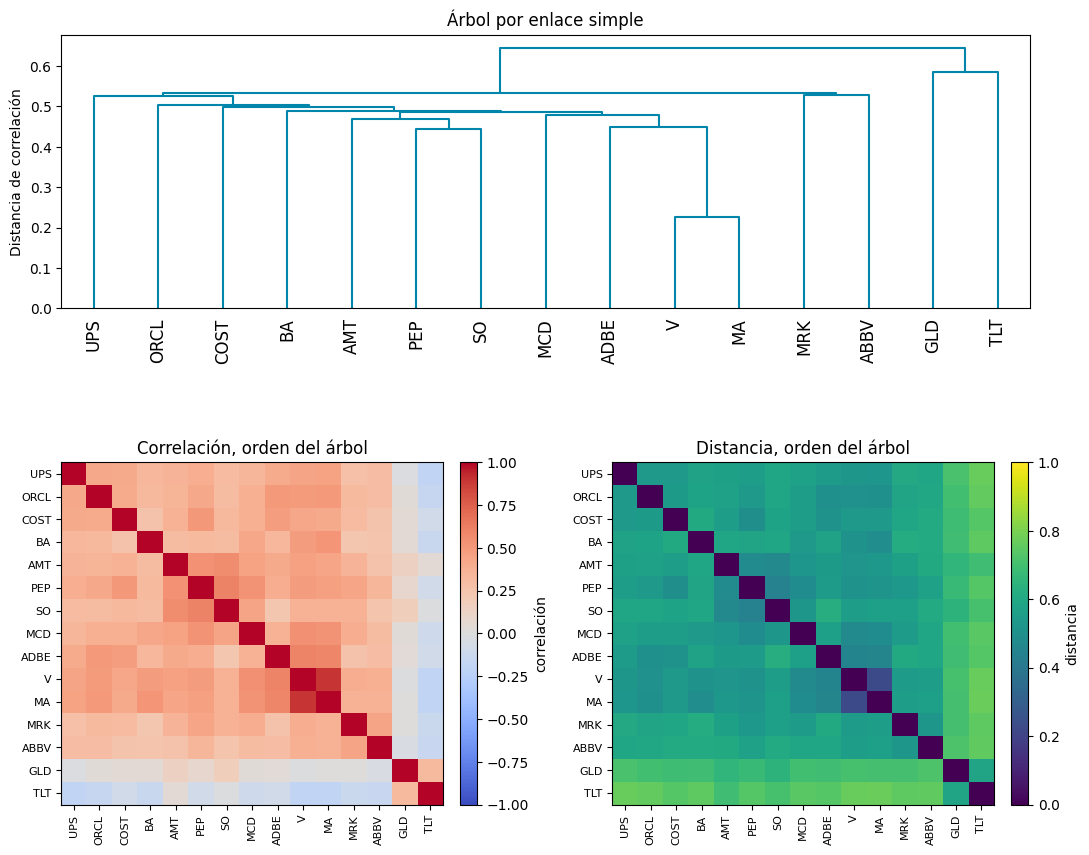

In [ ]:
fig = plt.figure(figsize=(12.5, 10))
rejilla = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.5, wspace=0.32)
ax_arbol = fig.add_subplot(rejilla[0, :])
dendrogram(enlace, labels=nombres, leaf_rotation=90, color_threshold=0,
           above_threshold_color="#0086AB", ax=ax_arbol)
ax_arbol.set_title("Árbol por enlace simple")
ax_arbol.set_ylabel("Distancia de correlación")

def mapa(ax, matriz, titulo, vmin, vmax, cmap, etiqueta):
    imagen = ax.imshow(matriz.loc[orden, orden], cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(orden))); ax.set_yticks(range(len(orden)))
    ax.set_xticklabels(orden, rotation=90, fontsize=8); ax.set_yticklabels(orden, fontsize=8)
    ax.set_title(titulo)
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04, label=etiqueta)

mapa(fig.add_subplot(rejilla[1, 0]), correlacion, "Correlación, orden del árbol", -1, 1, "coolwarm", "correlación")
mapa(fig.add_subplot(rejilla[1, 1]), distancia_df, "Distancia, orden del árbol", 0, 1, "viridis", "distancia")
plt.show()

## 7. Primer corte y paridad jerárquica
El lado izquierdo se queda con $\alpha = v_1/(v_0+v_1)$. $v$ es la varianza de la canasta de varianza inversa de cada lado.

In [ ]:
covarianza = retornos.cov()

def varianza_racimo(cov, grupo):
    sub = cov.loc[list(grupo), list(grupo)].values
    ivp = 1.0 / np.diag(sub)
    ivp = ivp / ivp.sum()
    return float(ivp @ sub @ ivp)

def biseccion(cov, lista):
    pesos = pd.Series(1.0, index=list(lista))
    def partir(grupo):
        if len(grupo) <= 1:
            return
        k = len(grupo) // 2
        izq, der = grupo[:k], grupo[k:]
        v0, v1 = varianza_racimo(cov, izq), varianza_racimo(cov, der)
        alfa = v1 / (v0 + v1)
        pesos[izq] *= alfa
        pesos[der] *= 1.0 - alfa
        partir(izq); partir(der)
    partir(list(lista))
    return pesos

izquierda, derecha = orden[: n // 2], orden[n // 2 :]
v0, v1 = varianza_racimo(covarianza, izquierda), varianza_racimo(covarianza, derecha)
alfa = v1 / (v0 + v1)
print("Izquierda:", izquierda)
print("  volatilidad anual", round((v0 * 252) ** 0.5, 3), "· capital", round(alfa, 3))
print("Derecha:  ", derecha)
print("  volatilidad anual", round((v1 * 252) ** 0.5, 3), "· capital", round(1 - alfa, 3))

pesos_hrp = biseccion(covarianza, orden).reindex(nombres)
print("\nSuma de pesos HRP:", round(pesos_hrp.sum(), 6))
print("Coincide la izquierda con alfa:", np.isclose(pesos_hrp[izquierda].sum(), alfa))

Izquierda: ['UPS', 'ORCL', 'COST', 'BA', 'AMT', 'PEP', 'SO']
  volatilidad anual 0.166 · capital 0.28
Derecha:   ['MCD', 'ADBE', 'V', 'MA', 'MRK', 'ABBV', 'GLD', 'TLT']
  volatilidad anual 0.103 · capital 0.72

Suma de pesos HRP: 1.0
Coincide la izquierda con alfa: True


## 8. Mínima varianza y varianza inversa

In [ ]:
def varianza_inversa(cov):
    ivp = 1.0 / np.diag(cov.values)
    return pd.Series(ivp / ivp.sum(), index=cov.index)

def minima_varianza(cov):
    k = cov.shape[0]
    sigma = cov.values
    solucion = minimize(lambda w: float(w @ sigma @ w), np.full(k, 1.0 / k), method="SLSQP",
                        bounds=[(0.0, 1.0)] * k,
                        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
                        options={"maxiter": 1000, "ftol": 1e-12})
    if not solucion.success:
        raise RuntimeError(solucion.message)
    return pd.Series(solucion.x, index=cov.index)

pesos_pvi = varianza_inversa(covarianza)
pesos_pmv = minima_varianza(covarianza)
print("Suma PMV:", round(pesos_pmv.sum(), 6), "· suma PVI:", round(pesos_pvi.sum(), 6))

Suma PMV: 1.0 · suma PVI: 1.0


## 9. Pesos y concentración
Número efectivo $=1/\sum w_i^2$ (15 si todos pesaran igual). Un peso menor que $10^{-4}$ cuenta como cero.

In [ ]:
portafolios = pd.DataFrame({"PMV": pesos_pmv, "PVI": pesos_pvi, "HRP": pesos_hrp})

def concentracion(pesos):
    return pd.Series({
        "peso_maximo": round(pesos.max(), 4),
        "activo": pesos.idxmax(),
        "ceros": int((pesos < 1e-4).sum()),
        "numero_efectivo": round(1.0 / np.sum(pesos ** 2), 2),
    })

print(portafolios.round(4).sort_values("HRP", ascending=False))
print()
print(portafolios.apply(concentracion).T)
print("\nDiferencia HRP − PVI (puntos porcentuales):")
print(((portafolios["HRP"] - portafolios["PVI"]) * 100).round(2).sort_values())

         PMV     PVI     HRP
GLD   0.2786  0.1626  0.2371
TLT   0.3314  0.1357  0.1980
MRK   0.0806  0.0696  0.0933
ABBV  0.0497  0.0452  0.0606
MCD   0.0695  0.0762  0.0580
PEP   0.0445  0.0907  0.0548
UPS   0.0619  0.0490  0.0507
COST  0.0494  0.0680  0.0504
SO    0.0000  0.0659  0.0398
AMT   0.0000  0.0492  0.0374
ORCL  0.0146  0.0430  0.0319
V     0.0198  0.0527  0.0280
MA    0.0000  0.0435  0.0232
ADBE  0.0000  0.0292  0.0222
BA    0.0000  0.0194  0.0147

    peso_maximo activo ceros numero_efectivo
PMV      0.3314    TLT     5            4.76
PVI      0.1626    GLD     0           11.45
HRP      0.2371    GLD     0            7.98

Diferencia HRP − PVI (puntos porcentuales):
PEP    -3.60
SO     -2.61
V      -2.46
MA     -2.04
MCD    -1.81
COST   -1.76
AMT    -1.18
ORCL   -1.11
ADBE   -0.69
BA     -0.47
UPS     0.17
ABBV    1.54
MRK     2.36
TLT     6.22
GLD     7.45
dtype: float64


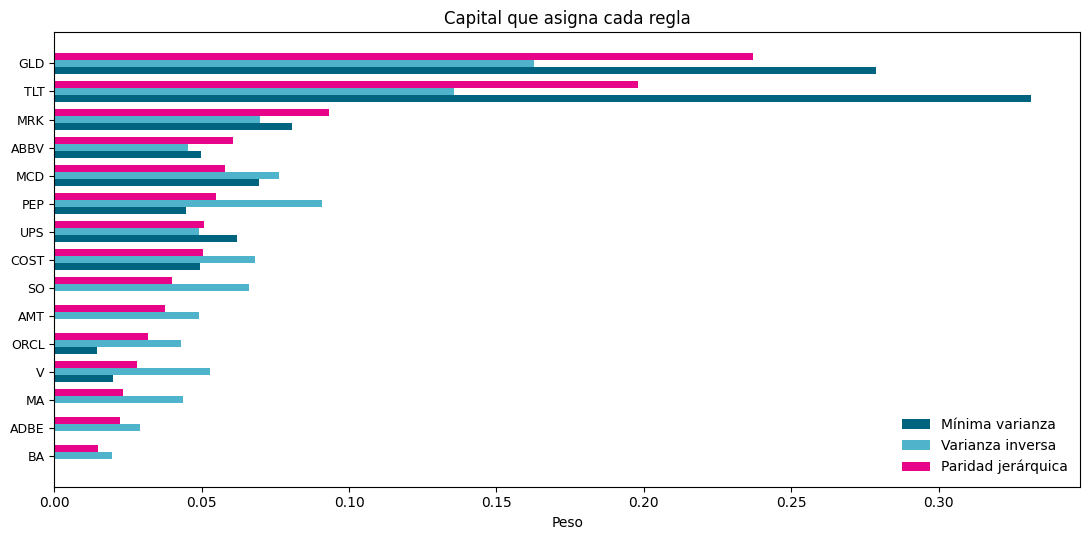

In [ ]:
ordenado = portafolios.sort_values("HRP")
y = np.arange(len(ordenado))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(y - 0.25, ordenado["PMV"], height=0.25, color="#00637F", label="Mínima varianza")
ax.barh(y, ordenado["PVI"], height=0.25, color="#4FB3CC", label="Varianza inversa")
ax.barh(y + 0.25, ordenado["HRP"], height=0.25, color="#E70488", label="Paridad jerárquica")
ax.set_yticks(y); ax.set_yticklabels(ordenado.index, fontsize=9)
ax.set_xlabel("Peso"); ax.set_title("Capital que asigna cada regla")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

## 10. Rentabilidad en las dos ventanas
Retorno anual = media diaria × 252 · volatilidad = desviación diaria × √252 · Sharpe = retorno / volatilidad (tasa libre de riesgo 0) · caída máxima sobre la riqueza $\prod(1+R)$.

In [ ]:
def serie_portafolio(r, pesos):
    return pd.DataFrame({c: r @ pesos[c] for c in pesos.columns})

dentro = serie_portafolio(retornos, portafolios)
fuera = serie_portafolio(retornos_prueba, portafolios)

def metricas(serie):
    riqueza = (1.0 + serie).cumprod()
    caida = riqueza / riqueza.cummax() - 1.0
    return pd.Series({
        "retorno_anual": serie.mean() * 252,
        "volatilidad": serie.std() * np.sqrt(252),
        "sharpe": serie.mean() / serie.std() * np.sqrt(252),
        "peor_dia": serie.min(),
        "caida_maxima": caida.min(),
    })

m_dentro = dentro.apply(metricas).T
m_fuera = fuera.apply(metricas).T
print("Dentro de la muestra"); print(m_dentro.round(3))
print("\nFuera de la muestra"); print(m_fuera.round(3))

Dentro de la muestra
     retorno_anual  volatilidad  sharpe  peor_dia  caida_maxima
PMV          0.082        0.089   0.917    -0.037        -0.162
PVI          0.124        0.116   1.063    -0.077        -0.192
HRP          0.107        0.100   1.069    -0.056        -0.145

Fuera de la muestra
     retorno_anual  volatilidad  sharpe  peor_dia  caida_maxima
PMV          0.104        0.105   0.989    -0.029        -0.125
PVI          0.099        0.105   0.945    -0.039        -0.098
HRP          0.110        0.106   1.040    -0.033        -0.100


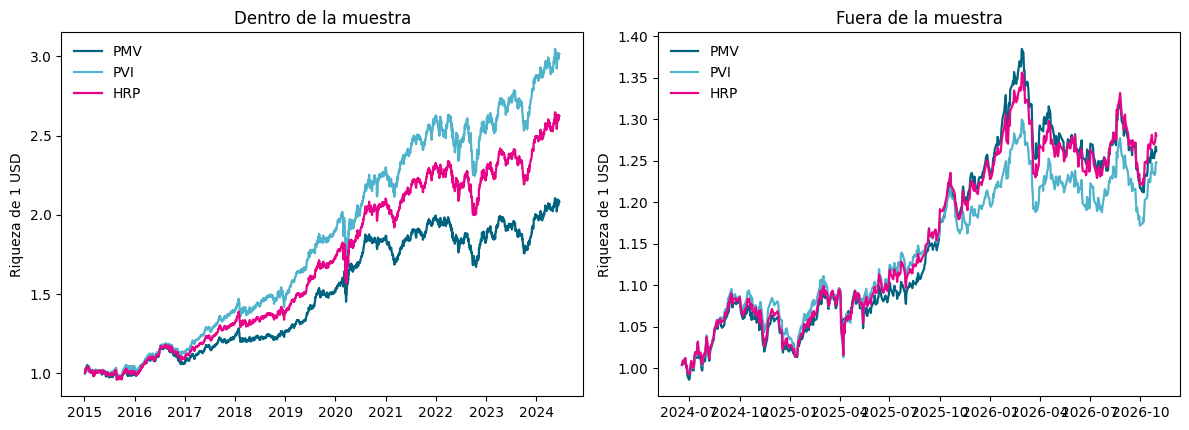

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4))
colores = {"PMV": "#00637F", "PVI": "#4FB3CC", "HRP": "#E70488"}
for ax, serie, titulo in ((ejes[0], dentro, "Dentro de la muestra"), (ejes[1], fuera, "Fuera de la muestra")):
    riqueza = (1 + serie).cumprod()
    for c in ["PMV", "PVI", "HRP"]:
        ax.plot(riqueza.index, riqueza[c], color=colores[c], label=c, lw=1.6)
    ax.set_title(titulo); ax.set_ylabel("Riqueza de 1 USD"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## 11. Tabla de rentabilidad del taller

In [ ]:
conc = portafolios.apply(concentracion).T
tabla = pd.DataFrame({
    "Retorno anual, entrenamiento": m_dentro["retorno_anual"],
    "Sharpe, entrenamiento": m_dentro["sharpe"],
    "Retorno anual, prueba": m_fuera["retorno_anual"],
    "Sharpe, prueba": m_fuera["sharpe"],
    "Caída máxima, prueba": m_fuera["caida_maxima"],
    "Número efectivo": conc["numero_efectivo"].astype(float),
    "Ceros": conc["ceros"].astype(int),
}).rename(index={"PMV": "Mínima varianza", "PVI": "Varianza inversa", "HRP": "Paridad jerárquica"})
tabla.round(3)

,"Retorno anual, entrenamiento","Sharpe, entrenamiento","Retorno anual, prueba","Sharpe, prueba","Caída máxima, prueba",Número efectivo,Ceros
Mínima varianza,0.082,0.917,0.104,0.989,-0.125,4.76,5
Varianza inversa,0.124,1.063,0.099,0.945,-0.098,11.45,0
Paridad jerárquica,0.107,1.069,0.110,1.040,-0.100,7.98,0


## 12. Tabla de rentabilidad y respuestas

Entrenamiento: 2015-01-05 → 2024-06-17 (2.379 días). Prueba: 2024-06-18 → 2026-10-30 (595 días).

| Técnica | Retorno anual, entrenamiento | Sharpe, entrenamiento | Retorno anual, prueba | Sharpe, prueba | Caída máxima, prueba | Número efectivo | Ceros |
|---|---|---|---|---|---|---|---|
| Mínima varianza | 8,2 % | 0,92 | 10,4 % | 0,99 | −12,5 % | 4,76 | 5 |
| Varianza inversa | 12,4 % | 1,06 | 9,9 % | 0,95 | −9,8 % | 11,45 | 0 |
| Paridad jerárquica | 10,7 % | 1,07 | 11,0 % | 1,04 | −10,0 % | 7,98 | 0 |

**Lectura del árbol.** La primera unión es V–MA, a distancia 0,226 (correlación 0,90): las dos redes de pago se mueven casi igual. TLT queda con correlación negativa frente a casi todas las acciones (−0,19 con MA, −0,18 con V y UPS), y GLD y TLT quedan en el extremo derecho del orden de hojas. El primer corte separa UPS, ORCL, COST, BA, AMT, PEP y SO (volatilidad anual 16,6 %) de MCD, ADBE, V, MA, MRK, ABBV, GLD y TLT (10,3 %). Por eso α = 0,28: el lado izquierdo recibe 28 % del capital y el derecho, más quieto, 72 %.

**1. Rentabilidad y Sharpe.** En el entrenamiento la varianza inversa gana en rentabilidad: 12,4 % anual, frente a 10,7 % de la paridad jerárquica y 8,2 % de la mínima varianza. En Sharpe gana la paridad jerárquica, 1,069 frente a 1,063, prácticamente un empate. La varianza inversa rinde más porque deja más capital en acciones (GLD + TLT suman 29,8 % frente a 43,5 % en la jerárquica). Pero esa exposición también sube la volatilidad a 11,6 % frente a 10,0 %, y la caída máxima a −19,2 % frente a −14,5 %. El Sharpe divide el retorno por la volatilidad: 1,7 puntos más de retorno no compensan 1,6 puntos más de volatilidad. La más rentable no es la que más paga por unidad de riesgo.

**2. Los ceros de la mínima varianza.** La mínima varianza apagó 5 activos: SO, AMT, MA, ADBE y BA. Puso 61 % del capital en TLT (33,1 %) y GLD (27,9 %). En el entrenamiento su rentabilidad bajó frente a las otras dos (8,2 % frente a 12,4 % y 10,7 %) y su Sharpe fue el peor (0,92). Quedó fuera el riesgo de las acciones más volátiles o más correlacionadas: aviación (BA), software (ADBE), el segundo emisor de pagos (MA, redundante con V) y los activos sensibles a tasas (SO y AMT). Lo que no quedó fuera fue el riesgo de duración: con un tercio en bonos a 20+ años, el portafolio depende de las tasas de interés. En la prueba tuvo la peor caída máxima (−12,5 %), aunque su retorno (10,4 %) superó al de la varianza inversa.

**3. Correlación.** Las dos técnicas usan 1/σ², pero la paridad jerárquica reparte primero entre racimos. Frente a la varianza inversa, sube GLD (+7,5 pp), TLT (+6,2 pp), MRK (+2,4 pp) y ABBV (+1,5 pp), y baja PEP (−3,6 pp), SO (−2,6 pp), V (−2,5 pp), MA (−2,0 pp), MCD y COST (−1,8 pp cada uno). La razón es el primer corte: el lado izquierdo, con acciones correlacionadas entre sí, recibe solo 28 %. Y V y MA, con correlación 0,90, se tratan como una sola apuesta dentro de su racimo. La separación sí se ve en la rentabilidad, no solo en la composición. En el entrenamiento la jerárquica rinde menos (10,7 % frente a 12,4 %), con Sharpe igual y una caída máxima menor (−14,5 % frente a −19,2 %). En la prueba rinde más (11,0 % frente a 9,9 %) y su Sharpe es mayor (1,04 frente a 0,95), con la misma caída (−10,0 % frente a −9,8 %).

**4. Dos ventanas.** En el entrenamiento el orden de rentabilidad es varianza inversa > paridad jerárquica > mínima varianza. En la prueba se invierte casi por completo: paridad jerárquica (11,0 %) > mínima varianza (10,4 %) > varianza inversa (9,9 %). La ganadora del entrenamiento quedó última. Eso dice que el retorno pasado no se traslada: los pesos se estiman con covarianzas, que son relativamente estables, pero el retorno de cada activo cambia de una ventana a otra. Además, la mínima varianza prometía la menor volatilidad (8,9 % dentro de la muestra) y en la prueba quedó en 10,5 %, igual que las otras dos. Calcular los pesos con el pasado y dejarlos fijos funciona como regla de riesgo, no como predicción de rentabilidad. Las diferencias de Sharpe en la prueba (0,95 a 1,04) son pequeñas y vienen de una sola ventana de 595 días.

**5. Concentración.** El número efectivo ordena las técnicas de más concentrada a más diversificada: mínima varianza 4,76, paridad jerárquica 7,98 y varianza inversa 11,45. La más concentrada no pagó más por unidad de riesgo: tuvo el Sharpe más bajo en el entrenamiento (0,92) y el intermedio en la prueba (0,99). También tuvo la peor caída de la prueba (−12,5 %). Juntó el capital en dos apuestas, oro y bonos largos, más que diversificar el riesgo. La paridad jerárquica, con un número efectivo intermedio, tuvo el mejor Sharpe en las dos ventanas (1,07 y 1,04) y la menor caída del entrenamiento (−14,5 %). La varianza inversa, la más repartida, rindió más en el entrenamiento, pero con la mayor caída de esa ventana (−19,2 %) y el peor Sharpe en la prueba. Más diversificación por número de nombres no equivale a más diversificación por racimos.
